# 1. Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score

pd.set_option('display.max_rows', None)

# 2. Exploratory Data Analysis (EDA)

In [2]:
df = pd.read_csv('Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv')

In [3]:
df.sample(5)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
7788,53,259,2,2,70,102,35,35,35.0,0.000000,...,32,0.0,0.0000,0,0,0.0,0.0000,0,0,BENIGN
50149,53,221,2,2,64,204,32,32,32.0,0.000000,...,20,0.0,0.0000,0,0,0.0,0.0000,0,0,BENIGN
165332,36686,116907,1,6,6,36,6,6,6.0,0.000000,...,20,0.0,0.0000,0,0,0.0,0.0000,0,0,BENIGN
205259,443,118766139,22,25,2145,7983,904,0,97.5,197.318874,...,20,764606.0,993394.5179,1467042,62170,58600000.0,493788.9288,58900000,58200000,BENIGN
143477,80,11556711,5,0,30,0,6,6,6.0,0.000000,...,20,5012.0,0.0000,5012,5012,11600000.0,0.0000,11600000,11600000,DDoS


In [4]:
print("Jumlah baris: ", df.shape[0])
print("Jumlah kolom: ", df.shape[1])

Jumlah baris:  225745
Jumlah kolom:  79


In [5]:
print("nama kolom: ", df.columns.tolist())

nama kolom:  [' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count'

In [6]:
# Membersihkan spasi di awal/akhir nama kolom
df.columns = df.columns.str.strip()

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225745 entries, 0 to 225744
Data columns (total 79 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Destination Port             225745 non-null  int64  
 1   Flow Duration                225745 non-null  int64  
 2   Total Fwd Packets            225745 non-null  int64  
 3   Total Backward Packets       225745 non-null  int64  
 4   Total Length of Fwd Packets  225745 non-null  int64  
 5   Total Length of Bwd Packets  225745 non-null  int64  
 6   Fwd Packet Length Max        225745 non-null  int64  
 7   Fwd Packet Length Min        225745 non-null  int64  
 8   Fwd Packet Length Mean       225745 non-null  float64
 9   Fwd Packet Length Std        225745 non-null  float64
 10  Bwd Packet Length Max        225745 non-null  int64  
 11  Bwd Packet Length Min        225745 non-null  int64  
 12  Bwd Packet Length Mean       225745 non-null  float64
 13 

In [8]:
df.describe()

C:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
C:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,225745.00000,2.257450e+05,225745.000000,225745.000000,225745.000000,2.257450e+05,225745.000000,225745.000000,225745.000000,225745.000000,...,225745.000000,225745.000000,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05
mean,8879.61946,1.624165e+07,4.874916,4.572775,939.463346,5.960477e+03,538.535693,27.882221,164.826715,214.907242,...,3.311497,21.482753,1.848261e+05,1.293436e+04,2.080849e+05,1.776201e+05,1.032214e+07,3.611943e+06,1.287813e+07,7.755355e+06
std,19754.64740,3.152437e+07,15.422874,21.755356,3249.403484,3.921834e+04,1864.128991,163.324159,504.892965,797.411073,...,12.270018,4.166799,7.979250e+05,2.102737e+05,9.002350e+05,7.842602e+05,2.185303e+07,1.275689e+07,2.692126e+07,1.983109e+07
min,0.00000,-1.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,80.00000,7.118000e+04,2.000000,1.000000,26.000000,0.000000e+00,6.000000,0.000000,6.000000,0.000000,...,1.000000,20.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,80.00000,1.452333e+06,3.000000,4.000000,30.000000,1.640000e+02,20.000000,0.000000,8.666667,5.301991,...,2.000000,20.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,80.00000,8.805237e+06,5.000000,5.000000,63.000000,1.160100e+04,34.000000,6.000000,32.000000,10.263203,...,4.000000,20.000000,1.878000e+03,0.000000e+00,1.878000e+03,1.862000e+03,8.239725e+06,0.000000e+00,8.253838e+06,7.422849e+06
max,65532.00000,1.199999e+08,1932.000000,2942.000000,183012.000000,5.172346e+06,11680.000000,1472.000000,3867.000000,6692.644993,...,1931.000000,52.000000,1.000000e+08,3.950000e+07,1.000000e+08,1.000000e+08,1.200000e+08,6.530000e+07,1.200000e+08,1.200000e+08


In [9]:
df['Label'].value_counts()

Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

C:\Users\ACER\AppData\Local\Temp\ipykernel_32728\2292890557.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Label', palette='viridis')


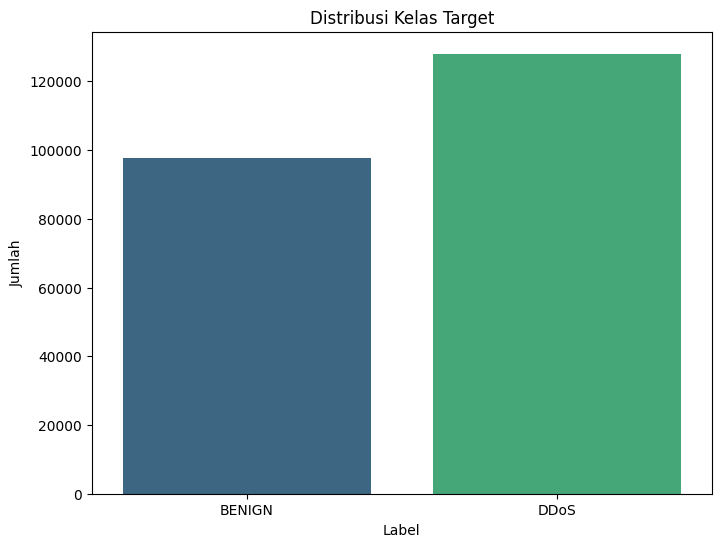

In [10]:
# Visualisasi distribusi kolom target 'Label'
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Label', palette='viridis')
plt.title('Distribusi Kelas Target')
plt.ylabel('Jumlah')
plt.show()

In [11]:
print("Data duplikat: ", df.duplicated().sum())

Data duplikat:  2633


In [12]:
print("Data missing: ", df.isnull().sum().sum())

Data missing:  4


In [13]:
df.nunique()

Destination Port                23950
Flow Duration                  187752
Total Fwd Packets                 297
Total Backward Packets            367
Total Length of Fwd Packets      3831
Total Length of Bwd Packets      6760
Fwd Packet Length Max            1891
Fwd Packet Length Min             151
Fwd Packet Length Mean           7401
Fwd Packet Length Std            9555
Bwd Packet Length Max            1945
Bwd Packet Length Min             343
Bwd Packet Length Mean           8655
Bwd Packet Length Std            9650
Flow Bytes/s                   202293
Flow Packets/s                 194094
Flow IAT Mean                  193666
Flow IAT Std                   159622
Flow IAT Max                   139745
Flow IAT Min                    11093
Fwd IAT Total                   78049
Fwd IAT Mean                    95095
Fwd IAT Std                     91184
Fwd IAT Max                     77978
Fwd IAT Min                      8820
Bwd IAT Total                  101942
Bwd IAT Mean

In [14]:
# Mengecek apakah ada nilai tak hingga (infinity) dalam DataFrame
np.isinf(df.select_dtypes(include=np.number)).sum()

Destination Port                0
Flow Duration                   0
Total Fwd Packets               0
Total Backward Packets          0
Total Length of Fwd Packets     0
Total Length of Bwd Packets     0
Fwd Packet Length Max           0
Fwd Packet Length Min           0
Fwd Packet Length Mean          0
Fwd Packet Length Std           0
Bwd Packet Length Max           0
Bwd Packet Length Min           0
Bwd Packet Length Mean          0
Bwd Packet Length Std           0
Flow Bytes/s                   30
Flow Packets/s                 34
Flow IAT Mean                   0
Flow IAT Std                    0
Flow IAT Max                    0
Flow IAT Min                    0
Fwd IAT Total                   0
Fwd IAT Mean                    0
Fwd IAT Std                     0
Fwd IAT Max                     0
Fwd IAT Min                     0
Bwd IAT Total                   0
Bwd IAT Mean                    0
Bwd IAT Std                     0
Bwd IAT Max                     0
Bwd IAT Min   

# 3. Data Preprocessing & Feature Engineering

## 3.1 Data Cleaning

In [15]:
# Menghapus baris duplikat
df = df.drop_duplicates()
print("Data duplikat setelah penghapusan: ", df.duplicated().sum())

Data duplikat setelah penghapusan:  0


In [16]:
# Mengganti nilai tak hingga (infinity) dengan NaN
kolom_numerik = df.select_dtypes(include=[np.number]).columns
df[kolom_numerik] = df[kolom_numerik].replace([np.inf, -np.inf], np.nan)
print("Jumlah nilai NaN setelah penggantian: ", df.isnull().sum().sum())

Jumlah nilai NaN setelah penggantian:  60


In [17]:
# Inputasi nilai NaN dengan median kolom
df[kolom_numerik] = df[kolom_numerik].fillna(df[kolom_numerik].median())
print("Jumlah nilai NaN setelah inputasi: ", df.isnull().sum().sum())

Jumlah nilai NaN setelah inputasi:  0


## 3.2 Split Data (20% / 80%)

Pembagian data di sini **sengaja dibalik** dari pembagian Machine Learning pada umumnya, supaya mengikuti paper.

Paper menuliskan bahwa **20% dataset dipakai untuk melatih algoritma dan menghasilkan centroid**, sedangkan **80% sisanya dipakai untuk menguji centroid tersebut**. Jadi `df_latih` yang kecil justru dipakai untuk *membangun* centroid, dan `df_uji` yang besar dipakai untuk *menilai*.

Perlu ditegaskan apa arti "melatih" di sini. K-Means adalah algoritma **tanpa label** — label tidak pernah dipakai saat menghitung centroid. Label pada 20% baru dipakai **setelah** centroid terbentuk, untuk memberi nama tiap centroid (lihat section 4). Itulah yang membuatnya semi-supervised: sedikit label dipakai untuk menamai hasil unsupervised, bukan untuk memfit model.

Parameter `stratify` dipakai agar proporsi BENIGN : DDoS tetap sama di kedua bagian.


In [18]:
df_latih, df_uji = train_test_split(df, test_size=0.80, random_state=42, stratify=df['Label'])

print("=== Pembagian data semi-supervised (20% / 80%) ===")
print(f"Total baris awal : {df.shape[0]}")
print(f"df_latih (20%)   : {df_latih.shape[0]}  -> dipakai membangun centroid")
print(f"df_uji   (80%)   : {df_uji.shape[0]}  -> dipakai menguji centroid")

print("\n=== Proporsi label di df_latih ===")
print((df_latih['Label'].value_counts(normalize=True) * 100).round(2))

print("\n=== Proporsi label di df_uji ===")
print((df_uji['Label'].value_counts(normalize=True) * 100).round(2))


=== Pembagian data semi-supervised (20% / 80%) ===
Total baris awal : 223112
df_latih (20%)   : 44622  -> dipakai membangun centroid
df_uji   (80%)   : 178490  -> dipakai menguji centroid

=== Proporsi label di df_latih ===
Label
DDoS      57.38
BENIGN    42.62
Name: proportion, dtype: float64

=== Proporsi label di df_uji ===
Label
DDoS      57.38
BENIGN    42.62
Name: proportion, dtype: float64


## 3.3 Feature Selection

In [19]:
X_latih = df_latih.drop(columns=['Label']).select_dtypes(include=[np.number])
y_latih = df_latih['Label']
y_latih_encoded = LabelEncoder().fit_transform(y_latih)

X_uji = df_uji.drop(columns=['Label']).select_dtypes(include=[np.number])
y_uji = df_uji['Label']
y_uji_encoded = LabelEncoder().fit_transform(y_uji)

print("Data latih:", X_latih.shape, "| Data uji:", X_uji.shape)


Data latih: (44622, 78) | Data uji: (178490, 78)


In [20]:
var_filter = VarianceThreshold(threshold=3)
var_filter.fit(X_latih)
survived_cols = X_latih.columns[var_filter.get_support()]
X_latih_var = X_latih[survived_cols]
print(f"Fitur setelah variance filter: {len(survived_cols)}")

Fitur setelah variance filter: 59


In [21]:
# =========================================================
# TAHAP 2: Information Gain
# =========================================================
def entropy_bits(counts):
    p = counts / counts.sum()
    p = p[p > 0]
    return -(p * np.log2(p)).sum()

def info_gain(x, y, n_bins=10, ratio=False):
    # diskretisasi equal-frequency, lalu hitung IG = H(Y) - H(Y|A)
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1))[1:-1])
    a = np.searchsorted(edges, x, side='left')
    joint = np.zeros((a.max() + 1, y.max() + 1))
    np.add.at(joint, (a, y), 1)
    h_y = entropy_bits(joint.sum(axis=0))
    n = joint.sum()
    h_y_a = sum(r.sum() / n * entropy_bits(r) for r in joint if r.sum() > 0)
    ig = h_y - h_y_a
    if ratio:  # Information Gain Ratio (rumus 2 di paper)
        h_a = entropy_bits(joint.sum(axis=1))
        return ig / h_a if h_a > 0 else 0.0
    return ig

ig_scores = [info_gain(X_latih_var[c].values, y_latih_encoded) for c in survived_cols]

In [22]:
ig_df = pd.DataFrame({'Feature': survived_cols, 'Weight': ig_scores})
ig_df = ig_df.sort_values(by='Weight', ascending=False)

top_features = ig_df[ig_df['Weight'] > 0.6]['Feature'].tolist()
print(f"Jumlah fitur terpilih: {len(top_features)}")
for i, f in enumerate(top_features, 1):
    print(f"{i}. {f}")

Jumlah fitur terpilih: 11
1. Destination Port
2. Total Length of Fwd Packets
3. Subflow Fwd Bytes
4. Avg Bwd Segment Size
5. Bwd Packet Length Mean
6. Total Length of Bwd Packets
7. Subflow Bwd Bytes
8. Bwd Packet Length Max
9. Fwd Packet Length Max
10. Avg Fwd Segment Size
11. Fwd Packet Length Mean


In [23]:
tabel_kolom = pd.DataFrame({
    "Jumlah nilai unik": [X_latih[f].nunique() for f in top_features],
    "Nilai baris pertama": [X_latih[f].iloc[0] for f in top_features],
}, index=top_features)
tabel_kolom.index.name = "Fitur"

pasangan_identik, pasangan_nyaris = [], []
for i, a in enumerate(top_features):
    for b in top_features[i + 1:]:
        beda = int((X_latih[a].to_numpy() != X_latih[b].to_numpy()).sum())
        if beda == 0:
            pasangan_identik.append((a, b, beda))
        elif np.allclose(X_latih[a], X_latih[b]):
            pasangan_nyaris.append((a, b, beda))

jumlah_pasangan = len(pasangan_identik) + len(pasangan_nyaris)
fitur_distinct = len(top_features) - jumlah_pasangan

print(tabel_kolom.to_string())
print()
print(f"Jumlah fitur terpilih         : {len(top_features)}")
print(f"Pasangan kolom identik        : {len(pasangan_identik)}")
print(f"Pasangan kolom nyaris identik : {len(pasangan_nyaris)}")
print(f"Jumlah fitur distinct         : {fitur_distinct}")
print()

print("Kolom duplikat (identik di semua baris):")
for a, b, _ in pasangan_identik:
    print(f"  {a:28s} == {b}")

print()
print("Kolom nyaris duplikat:")
for a, b, beda in pasangan_nyaris:
    print(f"  {a:28s} ~= {b}   (berbeda di {beda} dari {len(X_latih):,} baris)".replace(",", "."))

print()
print("Dampaknya: jarak Euclidean yang dipakai K-Means menghitung nilai fitur")
print("terduplikasi lebih dari sekali, sehingga bobot fitur tidak seimbang.")
print("Kelemahan ini terbawa dari paper ke implementasi kita.")

                             Jumlah nilai unik  Nilai baris pertama
Fitur                                                              
Destination Port                          7244                 80.0
Total Length of Fwd Packets               1657                 30.0
Subflow Fwd Bytes                         1657                 30.0
Avg Bwd Segment Size                      2353                  0.0
Bwd Packet Length Mean                    2353                  0.0
Total Length of Bwd Packets               2178                  0.0
Subflow Bwd Bytes                         2178                  0.0
Bwd Packet Length Max                      904                  0.0
Fwd Packet Length Max                      985                  6.0
Avg Fwd Segment Size                      2167                  6.0
Fwd Packet Length Mean                    2167                  6.0

Jumlah fitur terpilih         : 11
Pasangan kolom identik        : 3
Pasangan kolom nyaris identik : 1
Jumlah fitur

### 3.4 Perbandingan Fitur Terpilih dengan Paper

Tabel 2 pada paper mencantumkan 15 fitur terpilih beserta skor information gain-nya. Kita bisa mengecek apakah feature selection kita memilih fitur yang sama.

Catatan penting: skor information gain **tidak bisa dibandingkan angka per angka** dengan paper, karena cara diskretisasi WEKA tidak sepenuhnya sama dengan fungsi `info_gain` di cell sebelumnya. Yang bisa dibandingkan adalah **nama fitur** mana yang terpilih.

### 3.5 Pemeriksaan Fitur Duplikat

Sebelum lanjut, kita perlu memastikan 11 fitur terpilih benar-benar 11 informasi yang berbeda.

Ternyata tidak. Sebagian besar pasangan di antaranya ternyata **kolom duplikat** — nilainya identik di hampir seluruh baris. Ini menjelaskan kenapa skor information gain-nya keluar berpasangan sama.

Menariknya, **paper punya masalah yang sama persis**. Empat pasangan di Tabel 2 paper juga memiliki skor identik, dan pasangan-pasangan itu adalah kolom yang sama. Artinya klaim "84 menjadi 15 fitur" di paper sebenarnya hanya menghasilkan **11 fitur distinct**.

Cell ini mendokumentasikan temuan ini dengan memeriksa ketat, bukan hanya membandingkan skor.

In [24]:
FITUR_PAPER = [
    "Subflow Fwd Bytes",
    "Total Length of Fwd Packets",
    "Average Packet Size",
    "Total Length of Bwd Packets",
    "Subflow Bwd Bytes",
    "Bwd Packet Length Mean",
    "Avg Bwd Segment Size",
    "Fwd Header Length",
    "Destination Port",
    "Bwd Packet Length Max",
    "Init_Win_bytes_forward",
    "Avg Fwd Segment Size",
    "Fwd Packet Length Mean",
    "Fwd Packet Length Max",
    "Bwd Header Length",
]

AKURASI_PAPER_KMEANS = {2: 79.60, 4: 68.90, 6: 42.10}
AKURASI_PAPER_CANOPY = {2: 72.30, 4: 65.70, 6: 55.90}

NAMA_KELAS = {0: "Normal", 1: "DDoS"}

In [25]:
ig_ranking = ig_df.set_index('Feature')['Weight']

tabel_fs = pd.DataFrame({
    "Skor IG (data Friday)": [round(ig_ranking.loc[f], 4) for f in top_features],
    "Termasuk 15 fitur paper": ["Ya" if f in FITUR_PAPER else "Tidak" for f in top_features],
}, index=top_features)
tabel_fs.index.name = "Fitur"

print(f"Jumlah fitur terpilih : {len(top_features)}")
print(f"Jumlah fitur di paper : {len(FITUR_PAPER)}")
print()
print(tabel_fs.to_string())
print()

tambahan = sorted(set(top_features) - set(FITUR_PAPER))
kurang = sorted(set(FITUR_PAPER) - set(top_features))
print("Fitur kita yang tidak ada di paper :", tambahan or "tidak ada")
print("Fitur paper yang tidak terpilih   :", kurang or "tidak ada")
print()
if kurang:
    print("Skor IG fitur paper yang tidak terpilih:")
    for f in kurang:
        print(f"  - {f:30s} IG = {ig_ranking.get(f, float('nan')):.4f}")

Jumlah fitur terpilih : 11
Jumlah fitur di paper : 15

                             Skor IG (data Friday) Termasuk 15 fitur paper
Fitur                                                                     
Destination Port                            0.7768                      Ya
Total Length of Fwd Packets                 0.7145                      Ya
Subflow Fwd Bytes                           0.7145                      Ya
Avg Bwd Segment Size                        0.6898                      Ya
Bwd Packet Length Mean                      0.6898                      Ya
Total Length of Bwd Packets                 0.6852                      Ya
Subflow Bwd Bytes                           0.6852                      Ya
Bwd Packet Length Max                       0.6838                      Ya
Fwd Packet Length Max                       0.6627                      Ya
Avg Fwd Segment Size                        0.6611                      Ya
Fwd Packet Length Mean                      0

# 4. Model K-Means Semi-supervised

**Tujuan** — membangun klasifikasi yang meniru langkah demi langkah apa yang dilakukan paper, lalu menghasilkan dua centroid bernama **DDoS** dan **Normal**.

**Kenapa perlu (bagian 2.4 dan Tabel 3 paper)** — alurnya:

1. K-Means dijalankan pada data latih 20% **tanpa melihat label**, menghasilkan `k` centroid (titik rata-rata tiap cluster).
2. Label 20% dipakai untuk **menamai** centroid: cluster yang didominasi BENIGN diberi nama "Normal", yang didominasi DDoS diberi nama "DDoS". Inilah tahap semi-supervised-nya.
3. Data uji 80% diklasifikasi dengan **nearest centroid** — tiap baris masuk ke centroid terdekat, dan prediksinya adalah nama centroid tersebut.
4. Karena dataset asli tetap punya label, prediksi di 80% dibandingkan dengan label asli untuk menghitung akurasi.

**Catatan penting** — langkah 3 secara matematis setara dengan *nearest-mean classifier*. K-Means tidak "memprediksi" apa pun; ia hanya merangkum data menjadi beberapa titik pusat. Karena itu karakteristik datanya sangat menentukan hasil akhir, dan itu akan terlihat di section 5.

In [26]:
KELAS_DARI_NAMA = {v: k for k, v in NAMA_KELAS.items()}


def label_mayoritas(y, mask):
    nilai = np.asarray(y)[mask].astype(int)
    hitung = np.bincount(nilai)
    return int(np.argmax(hitung)) if hitung.size else -1


def semi_supervised_kmeans(X_latih, y_latih, X_uji, k, seed=42):
    y_latih = np.asarray(y_latih)
    km = KMeans(n_clusters=k, n_init=10, random_state=seed)
    km.fit(X_latih)

    nama_centroid = {}
    for c in range(k):
        anggota = km.labels_ == c
        nama_centroid[c] = NAMA_KELAS[label_mayoritas(y_latih, anggota)] if anggota.any() else f"Cluster {c}"

    prediksi = np.array([KELAS_DARI_NAMA[nama_centroid[c]] for c in km.predict(X_uji)])
    return km, nama_centroid, prediksi


X_latih_fs = df_latih[top_features]
X_uji_fs = df_uji[top_features]

km2, nama2, pred2 = semi_supervised_kmeans(X_latih_fs, y_latih_encoded, X_uji_fs, k=2)

print("Jumlah centroid yang dibentuk :", km2.n_clusters)
print("Nama centroid                 :", nama2)
print("Prediksi unik di data uji    :", sorted(set(pred2)))
print("Akurasi pada 80% data uji    : {:.2f}%".format(accuracy_score(y_uji_encoded, pred2) * 100))


Jumlah centroid yang dibentuk : 2
Nama centroid                 : {0: 'DDoS', 1: 'Normal'}
Prediksi unik di data uji    : [np.int64(0), np.int64(1)]
Akurasi pada 80% data uji    : 57.43%


### 4.1 Nilai Centroid (padanan Tabel 3 paper)

Setiap nilai centroid adalah rata-rata seluruh flow yang masuk ke cluster tersebut. Perhatikan bagaimana kedua centroid berbeda jauh pada fitur seperti `Total Length of Bwd Packets` — itulah yang membuat pemisahan DDoS dan Normal menjadi mungkin.

In [27]:
tabel_centroid = pd.DataFrame(km2.cluster_centers_, columns=top_features).round(2)
tabel_centroid.index = [f"Centroid {i + 1} ({nama2[c]})" for i, c in enumerate(sorted(nama2))]
print(tabel_centroid.to_string())
print()
print("Jumlah baris data latih di tiap centroid:")
for c in sorted(nama2):
    print(f"  {nama2[c]:8s} -> {(km2.labels_ == c).sum()} baris")

                     Destination Port  Total Length of Fwd Packets  Subflow Fwd Bytes  Avg Bwd Segment Size  Bwd Packet Length Mean  Total Length of Bwd Packets  Subflow Bwd Bytes  Bwd Packet Length Max  Fwd Packet Length Max  Avg Fwd Segment Size  Fwd Packet Length Mean
Centroid 1 (DDoS)             9161.41                       970.21             970.21                900.97                  900.97                      5280.18            5280.18                2767.61                 566.74                172.25                  172.25
Centroid 2 (Normal)            389.22                      9417.78            9417.78               1896.08                 1896.08                   1041645.85         1041645.85                4986.41                 614.63                 26.32                   26.32

Jumlah baris data latih di tiap centroid:
  DDoS     -> 44595 baris
  Normal   -> 27 baris


# 5. Eksperimen K = 2, 4, 6

**Tujuan** — mengulang eksperimen paper pada Tabel 4 dan membandingkan angkanya langsung.

**Kenapa perlu** — paper menguji jumlah centroid `k` = 2, 4, dan 6, lalu menyimpulkan **2 centroid adalah yang terbaik** (79.60%), lalu turun drastis di 4 centroid (68.90%) dan 6 centroid (42.10%). Kita ingin melihat apakah pola yang sama muncul di data Friday.

**Langkah** — jalankan `semi_supervised_kmeans()` untuk tiap `k`, hitung akurasi di 80% data uji, lalu bandingkan dengan angka paper.

In [28]:
def jalankan_semua_k(k_values=(2, 4, 6), seed=42):
    hasil = []
    for k in k_values:
        _, _, pred = semi_supervised_kmeans(X_latih_fs, y_latih_encoded, X_uji_fs, k, seed=seed)
        akurasi = accuracy_score(y_uji_encoded, pred) * 100
        hasil.append({"k": k, "Akurasi (%)": round(akurasi, 2)})
    return pd.DataFrame(hasil)


hasil_kmeans = jalankan_semua_k()
hasil_kmeans["Akurasi paper (%)"] = hasil_kmeans["k"].map(AKURASI_PAPER_KMEANS)
hasil_kmeans["Selisih (poin)"] = (hasil_kmeans["Akurasi (%)"] - hasil_kmeans["Akurasi paper (%)"]).round(2)

print("Perbandingan K-Means: data Friday vs paper")
print("-" * 62)
print(hasil_kmeans.to_string(index=False))
print("-" * 62)
k_terbaik = int(hasil_kmeans.loc[hasil_kmeans["Akurasi (%)"].idxmax(), "k"])
print("k optimum menurut data Friday:", k_terbaik)
print("k optimum menurut paper     : 2")

Perbandingan K-Means: data Friday vs paper
--------------------------------------------------------------
 k  Akurasi (%)  Akurasi paper (%)  Selisih (poin)
 2        57.43               79.6          -22.17
 4        73.23               68.9            4.33
 6        77.61               42.1           35.51
--------------------------------------------------------------
k optimum menurut data Friday: 6
k optimum menurut paper     : 2


# 6. Baseline: Canopy Clustering

**Tujuan** — menguji klaim utama paper bahwa K-Means lebih baik daripada algoritma clustering lain. Di Tabel 4, paper membandingkan K-Means dengan **Canopy**, dan K-Means menang di semua percobaan.

**Kenapa perlu** — tanpa baseline, angka 79.60% tidak berarti apa-apa; kita tidak tahu itu bagus atau jelek. Canopy juga tidak memakai label saat membentuk cluster, jadi adil untuk dibandingkan.

**Catatan implementasi** — paper memakai **WEKA**, sedangkan environment project ini tidak punya WEKA. Canopy ditulis manual mengikuti algoritma aslinya:

- satu titik acak dijadikan *center* pertama
- titik yang berjarak < `t2` dari center yang ada **tidak boleh** dipakai lagi sebagai center, supaya center tidak bertumpuk
- jumlah center dibatasi `k` agar sebanding dengan percobaan K-Means
- klasifikasi: titik dalam radius `t1` masuk ke center terdekat yang unik, titik selebihnya jatuh ke center terdekat

Supaya adil, Canopy di section ini dijalankan pada **fitur mentah tanpa penskalaan**, sama seperti K-Means. Versi berskala ada di section 8.

In [29]:
def canopy_clustering(X_latih, y_latih, X_uji, k, t1=0.7, t2=0.2, seed=42):
    y_latih = np.asarray(y_latih)
    A = np.asarray(X_latih, dtype=float)
    B = np.asarray(X_uji, dtype=float)
    rng = np.random.default_rng(seed)

    centers = [A[rng.integers(len(A))]]
    while len(centers) < k:
        d = np.linalg.norm(A[:, None, :] - np.array(centers)[None, :, :], axis=2).min(axis=1)
        kandidat = np.flatnonzero(d >= t2)
        if kandidat.size == 0:
            break
        centers.append(A[rng.choice(kandidat)])
    centers = np.array(centers)

    def kelompok(Z):
        d = np.linalg.norm(Z[:, None, :] - centers[None, :, :], axis=2)
        dalam = d < t1
        return np.where(dalam.any(axis=1), dalam.argmax(axis=1), d.argmin(axis=1))

    ke_latih = kelompok(A)
    ke_uji = kelompok(B)

    nama = {}
    for c in range(len(centers)):
        anggota = ke_latih == c
        nama[c] = NAMA_KELAS[label_mayoritas(y_latih, anggota)] if anggota.any() else f"Cluster {c}"

    prediksi = np.array([KELAS_DARI_NAMA[nama[c]] for c in ke_uji])
    return centers, nama, prediksi


def jalankan_canopy(k_values=(2, 4, 6), seed=42):
    hasil = []
    for k in k_values:
        _, _, pred = canopy_clustering(X_latih_fs, y_latih_encoded, X_uji_fs, k=k, seed=seed)
        hasil.append({"k": k, "Akurasi (%)": round(accuracy_score(y_uji_encoded, pred) * 100, 2)})
    return pd.DataFrame(hasil)


hasil_canopy = jalankan_canopy()
hasil_canopy["Akurasi paper (%)"] = hasil_canopy["k"].map(AKURASI_PAPER_CANOPY)
hasil_canopy["Selisih (poin)"] = (hasil_canopy["Akurasi (%)"] - hasil_canopy["Akurasi paper (%)"]).round(2)

print("Perbandingan Canopy: data Friday vs paper")
print("-" * 62)
print(hasil_canopy.to_string(index=False))


Perbandingan Canopy: data Friday vs paper
--------------------------------------------------------------
 k  Akurasi (%)  Akurasi paper (%)  Selisih (poin)
 2        77.86               72.3            5.56
 4        77.86               65.7           12.16
 6        77.86               55.9           21.96


### 6.1 K-Means vs Canopy

Paper menyimpulkan K-Means mengungguli Canopy di semua percobaan. Mari lihat apakah kesimpulan itu berlaku di sini.

In [30]:
perbandingan = hasil_kmeans.merge(hasil_canopy, on="k", suffixes=("_KMeans", "_Canopy"))
print(perbandingan.to_string(index=False))
print()

selisih = (perbandingan["Akurasi (%)_KMeans"] - perbandingan["Akurasi (%)_Canopy"]).round(2)
print("Selisih K-Means - Canopy :", selisih.tolist())
print("K-Means menang di", int((selisih > 0).sum()), "dari", len(selisih), "percobaan")

 k  Akurasi (%)_KMeans  Akurasi paper (%)_KMeans  Selisih (poin)_KMeans  Akurasi (%)_Canopy  Akurasi paper (%)_Canopy  Selisih (poin)_Canopy
 2               57.43                      79.6                 -22.17               77.86                      72.3                   5.56
 4               73.23                      68.9                   4.33               77.86                      65.7                  12.16
 6               77.61                      42.1                  35.51               77.86                      55.9                  21.96

Selisih K-Means - Canopy : [-20.43, -4.63, -0.25]
K-Means menang di 0 dari 3 percobaan


### 6.2 Mengapa akurasi Canopy persis sama untuk k = 2, 4, dan 6?

Tabel sebelumnya menunjukkan akurasi Canopy yang **sama persis** di tiga percobaan. Ini bukan kesalahan perhitungan, dan cell ini membuktikannya.

Kuncinya ada pada **penamaan centroid**. Pada setiap percobaan, hanya **satu** center yang berakhir diberi nama "Normal"; seluruh center lainnya bernama "DDoS". Akibatnya keputusan klasifikasi tetap pada satu batas saja: titik yang lebih dekat ke center Normal, sisanya DDoS. Menambah center hanya membagi ulang sisi DDoS menjadi kelompok-kelompok kecil yang semuanya tetap berlabel DDoS, sehingga batas keputusannya tidak berpindah.

In [31]:
print("Sebagian besar titik data uji jatuh ke center mana, dan center mana yang bernama Normal")
print("=" * 70)

for k in (2, 4, 6):
    C, nama, pred = canopy_clustering(X_latih_fs, y_latih_encoded, X_uji_fs, k=k, seed=42)
    jarak = np.linalg.norm(np.asarray(X_uji_fs, dtype=float)[:, None, :] - C[None, :, :], axis=2)
    ke = jarak.argmin(axis=1)

    print(f"\nk = {k}")
    print("-" * 70)
    for c in range(len(C)):
        print(f"    center {c} ({nama[c]:6s}) -> {int((ke == c).sum()):>7d} titik")

    n_normal = sum(1 for c in nama if nama[c] == "Normal")
    print(f"    center bernama Normal : {n_normal} dari {len(C)}")
    print(f"    akurasi              : {accuracy_score(y_uji_encoded, pred) * 100:.2f}%")

print()
print("=" * 70)
print("Pada ketiga percobaan hanya ada SATU center bernama Normal, sehingga batas")
print("keputusan Normal atau DDoS tetap sama persis. Center tambahan hanya membagi")
print("sisi DDoS menjadi kelompok-kelompok yang semuanya tetap berlabel DDoS.")

Sebagian besar titik data uji jatuh ke center mana, dan center mana yang bernama Normal



k = 2
----------------------------------------------------------------------
    center 0 (DDoS  ) ->   67163 titik
    center 1 (Normal) ->  111327 titik
    center bernama Normal : 1 dari 2
    akurasi              : 77.86%



k = 4
----------------------------------------------------------------------
    center 0 (DDoS  ) ->   15430 titik
    center 1 (Normal) ->  111327 titik
    center 2 (DDoS  ) ->   33279 titik
    center 3 (DDoS  ) ->   18454 titik
    center bernama Normal : 1 dari 4
    akurasi              : 77.86%



k = 6
----------------------------------------------------------------------
    center 0 (DDoS  ) ->   15430 titik
    center 1 (Normal) ->  111327 titik
    center 2 (DDoS  ) ->   11367 titik
    center 3 (DDoS  ) ->   18454 titik
    center 4 (DDoS  ) ->    8011 titik
    center 5 (DDoS  ) ->   13901 titik
    center bernama Normal : 1 dari 6
    akurasi              : 77.86%

Pada ketiga percobaan hanya ada SATU center bernama Normal, sehingga batas
keputusan Normal atau DDoS tetap sama persis. Center tambahan hanya membagi
sisi DDoS menjadi kelompok-kelompok yang semuanya tetap berlabel DDoS.


# 7. Visualisasi dan Perbandingan

**Tujuan** — menyajikan hasil secara visual agar mudah dimasukkan ke poster.

**Langkah**
1. Diagram batang: akurasi K-Means vs Canopy untuk tiap `k`, dengan penanda angka paper.
2. Confusion matrix untuk `k` terbaik, beserta nilai recall tiap kelas.
3. Sebaran nilai satu fitur kunci pada dua cluster, untuk menunjukkan mengapa `k=2` masuk akal.

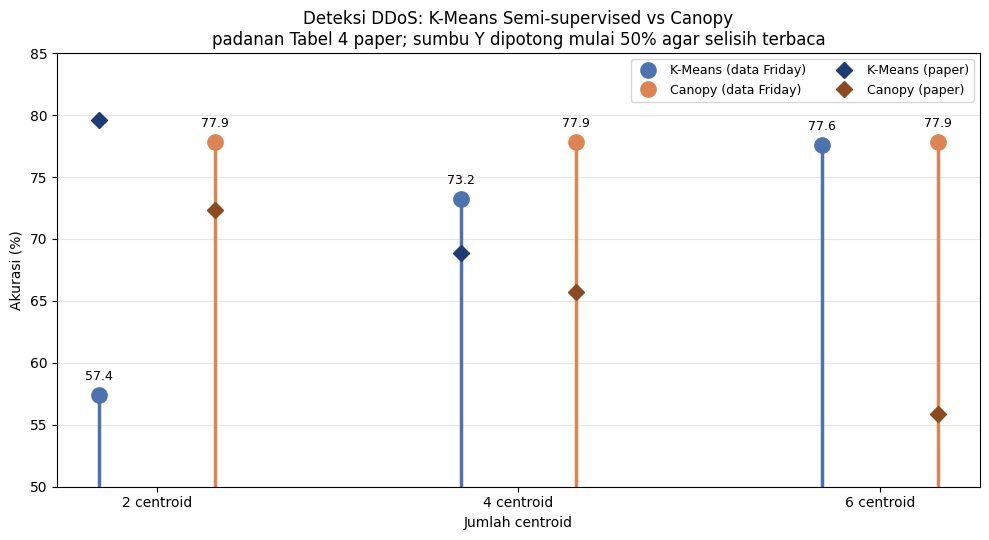

In [32]:
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(perbandingan))
off = 0.16

for i, (_, r) in enumerate(perbandingan.iterrows()):
    ax.vlines(i - off, 50, r["Akurasi (%)_KMeans"], color="#4C72B0", linewidth=2.5)
    ax.plot(i - off, r["Akurasi (%)_KMeans"], "o", color="#4C72B0", markersize=11,
            label="K-Means (data Friday)" if i == 0 else None)

    ax.vlines(i + off, 50, r["Akurasi (%)_Canopy"], color="#DD8452", linewidth=2.5)
    ax.plot(i + off, r["Akurasi (%)_Canopy"], "o", color="#DD8452", markersize=11,
            label="Canopy (data Friday)" if i == 0 else None)

    ax.plot(i - off, r["Akurasi paper (%)_KMeans"], "D", color="#1F3B73", markersize=8,
            label="K-Means (paper)" if i == 0 else None)
    ax.plot(i + off, r["Akurasi paper (%)_Canopy"], "D", color="#8C4A1F", markersize=8,
            label="Canopy (paper)" if i == 0 else None)

    ax.text(i - off, r["Akurasi (%)_KMeans"] + 1.2, f"{r['Akurasi (%)_KMeans']:.1f}", ha="center", fontsize=9)
    ax.text(i + off, r["Akurasi (%)_Canopy"] + 1.2, f"{r['Akurasi (%)_Canopy']:.1f}", ha="center", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels([f"{k} centroid" for k in perbandingan["k"]])
ax.set_ylim(50, 85)
ax.set_yticks(range(50, 90, 5))
ax.set_xlabel("Jumlah centroid")
ax.set_ylabel("Akurasi (%)")
ax.set_title("Deteksi DDoS: K-Means Semi-supervised vs Canopy\n"
             "padanan Tabel 4 paper; sumbu Y dipotong mulai 50% agar selisih terbaca")
ax.grid(axis="y", alpha=0.3)
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

### 7.1 Confusion Matrix

Matriks konfusi untuk k terbaik. Perhatikan jumlah pada baris "Aktual: DDoS": hanya 65.027 dari 102.413 flow serangan yang benar-benar terdeteksi.

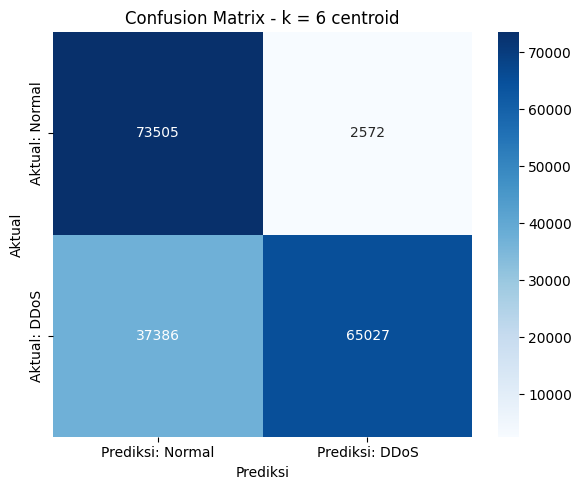

                Prediksi: Normal  Prediksi: DDoS
Aktual: Normal             73505            2572
Aktual: DDoS               37386           65027

Recall Normal : 96.62%
Recall DDoS   : 63.49%
Recall mikro  : 80.06%


In [33]:
from sklearn.metrics import confusion_matrix, recall_score

_, _, pred_terbaik = semi_supervised_kmeans(X_latih_fs, y_latih_encoded, X_uji_fs, k_terbaik)
cm = confusion_matrix(y_uji_encoded, pred_terbaik, labels=[0, 1])
df_cm = pd.DataFrame(cm, index=["Aktual: Normal", "Aktual: DDoS"],
                     columns=["Prediksi: Normal", "Prediksi: DDoS"])

plt.figure(figsize=(6, 5))
sns.heatmap(df_cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Confusion Matrix - k = {k_terbaik} centroid")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print(df_cm.to_string())
print()
print("Recall Normal : {:.2f}%".format(recall_score(y_uji_encoded, pred_terbaik, labels=[0], average='macro', zero_division=0) * 100))
print("Recall DDoS   : {:.2f}%".format(recall_score(y_uji_encoded, pred_terbaik, labels=[1], average='macro', zero_division=0) * 100))
print("Recall mikro  : {:.2f}%".format(recall_score(y_uji_encoded, pred_terbaik, average='macro', zero_division=0) * 100))

### 7.2 Precision, Recall, F1, dan False Positive Rate

Accuracy 77,61% terlihat biasa saja. Tapi accuracy bisa menipu, jadi kita perinci.

Perhatikan angka pada confusion matrix di atas: dari **102.413** flow DDoS, hanya **65.027** yang benar-benar terdeteksi. Itu berarti **37.386 serangan lolos** tanpa terdeteksi. Di konteks keamanan, serangan yang lolos justru kasus yang paling berbahaya.

Cell ini menguraikan accuracy menjadi metrik yang lebih informatif.

In [34]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report)

print(f"Laporan klasifikasi untuk k = {k_terbaik} centroid")
print("=" * 62)
print(classification_report(y_uji_encoded, pred_terbaik, labels=[0, 1],
                            target_names=["Normal", "DDoS"], digits=3, zero_division=0))

TN, FP, FN, TP = cm.ravel()

ringkas_metric = pd.DataFrame({
    "Metric": [
        "Accuracy (overall)",
        "Precision DDoS",
        "Recall / sensitivitas DDoS",
        "F1-score DDoS",
        "Specificity / Recall Normal",
        "False Positive Rate",
        "F1-score macro",
    ],
    "Nilai": [
        f"{(TP + TN) / cm.sum() * 100:.2f}%",
        f"{TP / (TP + FP) * 100:.2f}%",
        f"{TP / (TP + FN) * 100:.2f}%",
        f"{2 * TP / (2 * TP + FP + FN) * 100:.2f}%",
        f"{TN / (TN + FP) * 100:.2f}%",
        f"{FP / (FP + TN) * 100:.2f}%",
        f"{f1_score(y_uji_encoded, pred_terbaik, average='macro', zero_division=0) * 100:.2f}%",
    ],
})
print(ringkas_metric.to_string(index=False))
print()
print(f"Serangan DDoS yang lolos tidak terdeteksi : {FN:,} dari {FN + TP:,} flow".replace(",", "."))
print(f"Tingkat deteksi serangan                  : {TP / (TP + FN) * 100:.2f}%")

Laporan klasifikasi untuk k = 6 centroid
              precision    recall  f1-score   support

      Normal      0.663     0.966     0.786     76077
        DDoS      0.962     0.635     0.765    102413

    accuracy                          0.776    178490
   macro avg      0.812     0.801     0.776    178490
weighted avg      0.834     0.776     0.774    178490



                     Metric  Nilai
         Accuracy (overall) 77.61%
             Precision DDoS 96.20%
 Recall / sensitivitas DDoS 63.49%
              F1-score DDoS 76.50%
Specificity / Recall Normal 96.62%
        False Positive Rate  3.38%
             F1-score macro 77.56%

Serangan DDoS yang lolos tidak terdeteksi : 37.386 dari 102.413 flow
Tingkat deteksi serangan                  : 63.49%


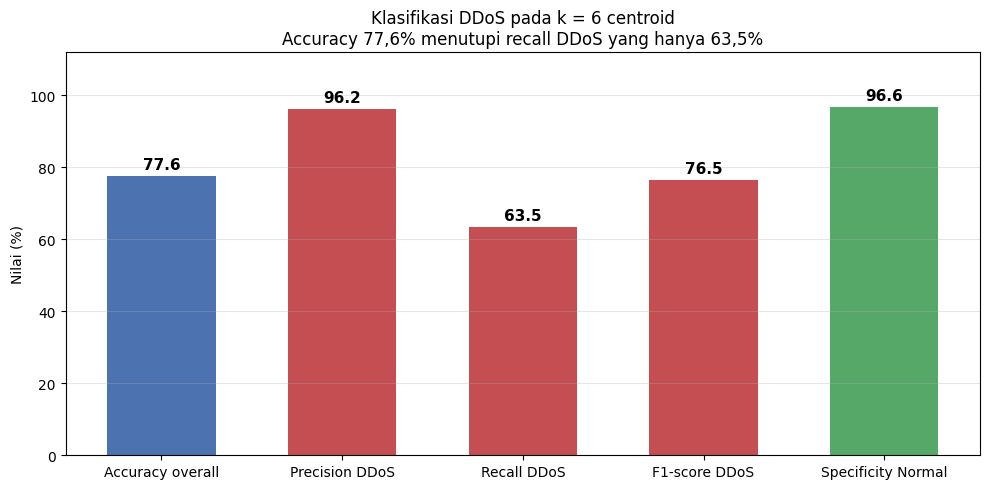

In [35]:
fig, ax = plt.subplots(figsize=(10, 5))
nilai_metric = [
    (TP + TN) / cm.sum(),
    TP / (TP + FP),
    TP / (TP + FN),
    2 * TP / (2 * TP + FP + FN),
    TN / (TN + FP),
]
warna_metric = ["#4C72B0", "#C44E52", "#C44E52", "#C44E52", "#55A868"]

bars = ax.bar(["Accuracy overall", "Precision DDoS", "Recall DDoS", "F1-score DDoS", "Specificity Normal"],
              [v * 100 for v in nilai_metric], color=warna_metric, width=0.6)

for b, v in zip(bars, nilai_metric):
    ax.text(b.get_x() + b.get_width() / 2, v * 100 + 2, f"{v * 100:.1f}",
            ha="center", fontsize=11, fontweight="bold")

ax.set_ylim(0, 112)
ax.set_ylabel("Nilai (%)")
ax.set_title(f"Klasifikasi DDoS pada k = {k_terbaik} centroid\n"
             "Accuracy 77,6% menutupi recall DDoS yang hanya 63,5%")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

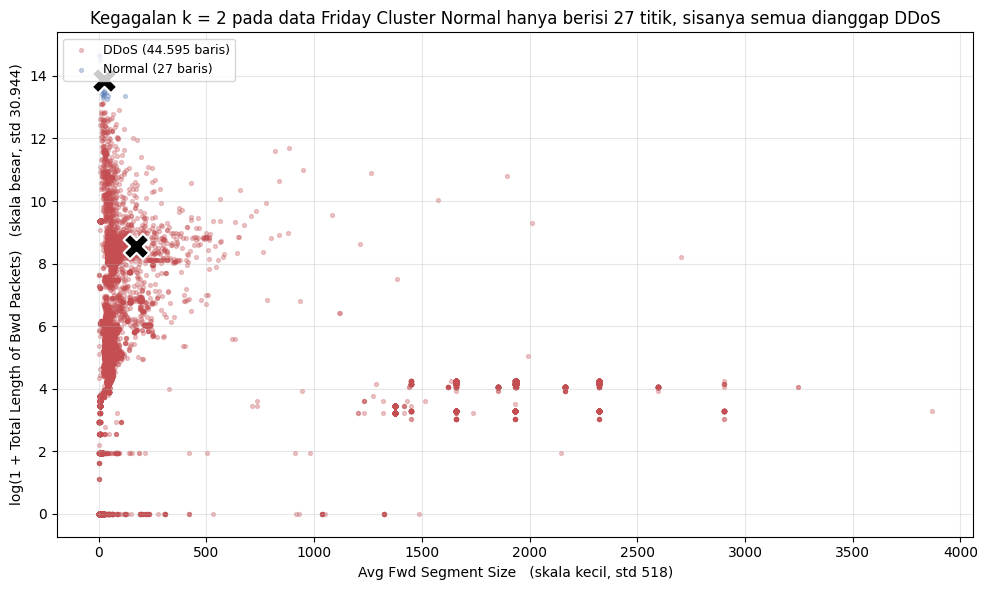

Rasio standar deviasi kedua sumbu: 59.7 kali
Karena itu jarak Euclidean dikuasai hampir seluruhnya oleh sumbu Y.


In [36]:
fitur_x, fitur_y = "Avg Fwd Segment Size", "Total Length of Bwd Packets"
warna_cluster = {"DDoS": "#C44E52", "Normal": "#4C72B0", "Cluster 0": "#999999", "Cluster 1": "#999999"}

ukuran_cluster = {nama2[c]: int((km2.labels_ == c).sum()) for c in sorted(nama2)}

plt.figure(figsize=(10, 6))
for c in sorted(nama2):
    anggota = np.flatnonzero(km2.labels_ == c)
    plt.scatter(
        X_latih_fs[fitur_x].to_numpy()[anggota],
        np.log1p(X_latih_fs[fitur_y].to_numpy()[anggota]),
        s=8, alpha=0.3,
        color=warna_cluster.get(nama2[c], "#999999"),
        label=f"{nama2[c]} ({ukuran_cluster[nama2[c]]:,} baris)".replace(",", "."),
    )

for c in sorted(nama2):
    cx = X_latih_fs.loc[km2.labels_ == c, fitur_x].mean()
    cy = np.log1p(X_latih_fs.loc[km2.labels_ == c, fitur_y].mean())
    plt.scatter(cx, cy, marker="X", s=340, color="black", edgecolors="white",
                linewidths=1.6, zorder=5)

plt.xlabel(f"{fitur_x}   (skala kecil, std 518)")
plt.ylabel(f"log(1 + {fitur_y})   (skala besar, std 30.944)")
plt.title("Kegagalan k = 2 pada data Friday Cluster Normal hanya berisi 27 titik, sisanya semua dianggap DDoS")
plt.legend(loc="upper left", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Rasio standar deviasi kedua sumbu:", round(30944 / 518, 1), "kali")
print("Karena itu jarak Euclidean dikuasai hampir seluruhnya oleh sumbu Y.")

# 8. Eksperimen Lanjut: Penskalaan Fitur

**Tujuan** — menguji dugaan bahwa rendahnya akurasi K-Means terutama disebabkan oleh **skala fitur yang tidak seragam**, bukan oleh algoritmanya sendiri.

**Hipotesis** — nilai fitur sangat berbeda jauh satu sama lain. Contohnya `Total Length of Bwd Packets` bernilai ribuan sampai jutaan, sementara `Destination Port` hanya 80. K-Means memakai jarak Euclidean, dan jarak seperti ini **dikuasai fitur yang angkanya besar**, sehingga fitur yang angkanya kecil praktis tidak berpengaruh apa pun. Solusinya: menormalkan setiap fitur ke rentang yang sama (StandardScaler) sebelum jaraknya dihitung.

**Penting** — section 5 dan 6 sengaja **tidak** memakai penskalaan, supaya hasilnya bisa dibandingkan langsung dengan angka paper. Section ini adalah variasi tambahan kita, bukan replika.

**Langkah**
1. Standardisasi fitur terpilih memakai mean/std dari data latih saja, agar tidak ada kebocoran informasi dari data uji.
2. Ulangi K-Means untuk `k` = 2, 4, 6.
3. Pilih `k` memakai silhouette score sebagai alasan, bukan asal tebak.

In [37]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_latih_fs)
X_latih_s = scaler.transform(X_latih_fs)
X_uji_s = scaler.transform(X_uji_fs)

hasil_scaled = pd.DataFrame({"k": hasil_kmeans["k"], "Tanpa penskalaan (%)": hasil_kmeans["Akurasi (%)"]})
hasil_scaled["Dengan penskalaan (%)"] = [
    round(accuracy_score(y_uji_encoded,
                         semi_supervised_kmeans(X_latih_s, y_latih_encoded, X_uji_s, k)[2]) * 100, 2)
    for k in hasil_kmeans["k"]
]
hasil_scaled["Selisih (poin)"] = (hasil_scaled["Dengan penskalaan (%)"] - hasil_scaled["Tanpa penskalaan (%)"]).round(2)

print("Pengaruh penskalaan fitur terhadap akurasi K-Means")
print("-" * 58)
print(hasil_scaled.to_string(index=False))
print("-" * 58)

Pengaruh penskalaan fitur terhadap akurasi K-Means
----------------------------------------------------------
 k  Tanpa penskalaan (%)  Dengan penskalaan (%)  Selisih (poin)
 2                 57.43                  63.93            6.50
 4                 73.23                  78.29            5.06
 6                 77.61                  78.34            0.73
----------------------------------------------------------


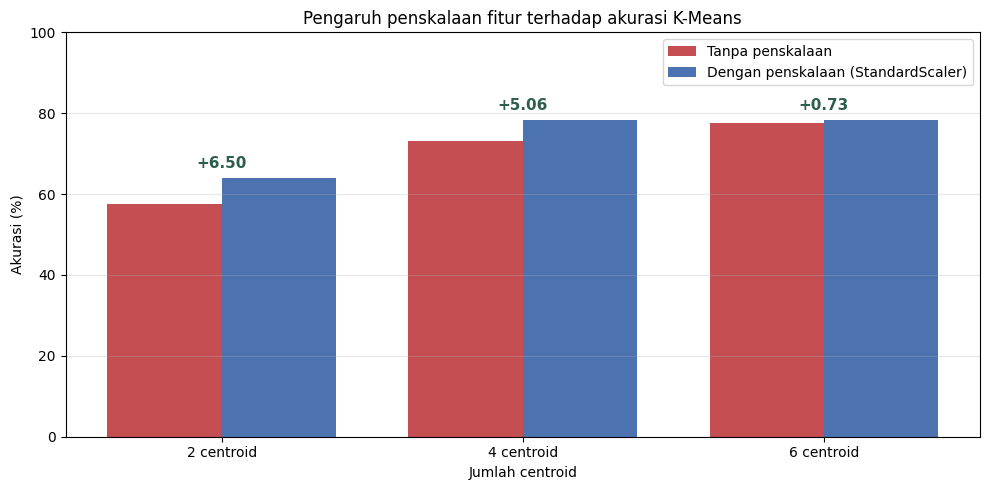

In [38]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(hasil_scaled))
w = 0.38

ax.bar(x - w / 2, hasil_scaled["Tanpa penskalaan (%)"], w, label="Tanpa penskalaan", color="#C44E52")
ax.bar(x + w / 2, hasil_scaled["Dengan penskalaan (%)"], w, label="Dengan penskalaan (StandardScaler)", color="#4C72B0")

for xi, (tanpa, dengan) in enumerate(zip(hasil_scaled["Tanpa penskalaan (%)"],
                                         hasil_scaled["Dengan penskalaan (%)"])):
    ax.annotate(f"+{dengan - tanpa:.2f}", xy=(xi, max(tanpa, dengan)),
                xytext=(0, 7), textcoords="offset points",
                ha="center", fontsize=11, fontweight="bold", color="#2E5E4E")

ax.set_xticks(x)
ax.set_xticklabels([f"{k} centroid" for k in hasil_scaled["k"]])
ax.set_ylim(0, 100)
ax.set_xlabel("Jumlah centroid")
ax.set_ylabel("Akurasi (%)")
ax.set_title("Pengaruh penskalaan fitur terhadap akurasi K-Means")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

Pemilihan k dengan silhouette score (data berskala, 5.000 sampel acak)
------------------------------------------------------


 k  Silhouette score
 2            0.7391
 3            0.7091
 4            0.7110
 5            0.7561
 6            0.7592
 7            0.7600
 8            0.7104

k terbaik menurut silhouette : 7
k terbaik menurut akurasi    : 6


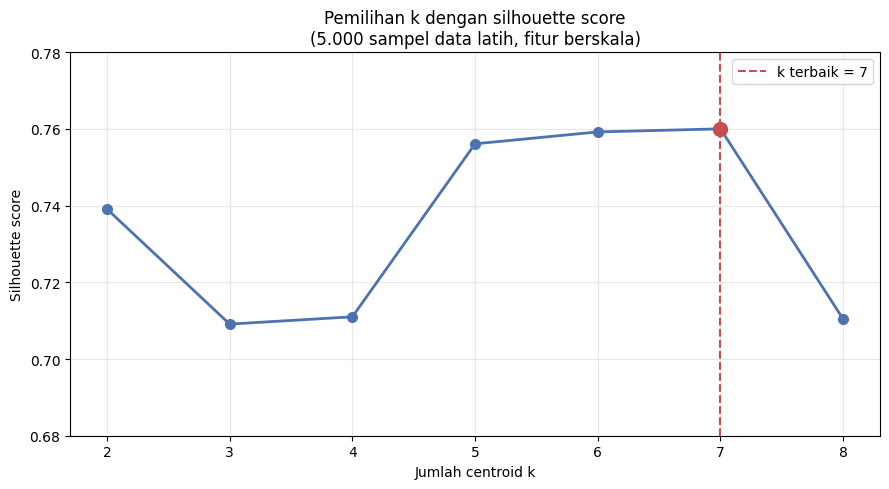

In [39]:
from sklearn.metrics import silhouette_score

print("Pemilihan k dengan silhouette score (data berskala, 5.000 sampel acak)")
print("-" * 54)

rng = np.random.default_rng(42)
idx = rng.choice(len(X_latih_s), 5000, replace=False)

baris_sil = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_latih_s[idx])
    baris_sil.append({"k": k, "Silhouette score": round(silhouette_score(X_latih_s[idx], km.labels_), 4)})

df_sil = pd.DataFrame(baris_sil)
print(df_sil.to_string(index=False))
k_silhouette = int(df_sil.loc[df_sil["Silhouette score"].idxmax(), "k"])
print()
print("k terbaik menurut silhouette :", k_silhouette)
print("k terbaik menurut akurasi    :", k_terbaik)
plt.figure(figsize=(9, 5))
plt.plot(df_sil["k"], df_sil["Silhouette score"], "o-", color="#4C72B0", linewidth=2, markersize=7)
plt.axvline(k_silhouette, color="#C44E52", linestyle="--", linewidth=1.5,
            label=f"k terbaik = {k_silhouette}")
plt.plot(k_silhouette, df_sil.loc[df_sil["k"] == k_silhouette, "Silhouette score"].iloc[0],
         "o", color="#C44E52", markersize=10)

plt.ylim(0.68, 0.78)
plt.xticks(df_sil["k"])
plt.xlabel("Jumlah centroid k")
plt.ylabel("Silhouette score")
plt.title("Pemilihan k dengan silhouette score\n(5.000 sampel data latih, fitur berskala)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 9. Kesimpulan

Tiga pertanyaan untuk dijawab di bagian ini:

1. Apakah feature selection paper bisa direplikasi di dataset CICIDS2017 yang berbeda?
2. Apakah akurasi K-Means semi-supervised mendekati angka paper?
3. Apa penyebab utamanya kalau angkanya berbeda?

Cell berikutnya merangkum semuanya dalam satu tabel.

In [40]:
tabel_akhir = pd.DataFrame({
    "Aspek": [
        "Jumlah fitur awal",
        "Setelah filter variance >= 3",
        "Setelah filter information gain > 0.6",
        "Jumlah fitur distinct (setelah cek duplikat)",
        "Jumlah fitur terpilih di paper",
        "Jumlah baris dataset",
        "k optimum menurut akurasi",
        "K-Means tanpa penskalaan",
        "K-Means dengan penskalaan",
        "K-Means di paper",
        "Canopy di data Friday",
        "Canopy di paper",
    ],
    "Project ini": [
        X_latih.shape[1] + 1,
        len(survived_cols),
        len(top_features),
        fitur_distinct,
        len(FITUR_PAPER),
        len(df),
        k_terbaik,
        f"{hasil_kmeans['Akurasi (%)'].max():.2f}%",
        f"{hasil_scaled['Dengan penskalaan (%)'].max():.2f}%",
        f"{max(AKURASI_PAPER_KMEANS.values()):.2f}%",
        f"{hasil_canopy['Akurasi (%)'].max():.2f}%",
        f"{max(AKURASI_PAPER_CANOPY.values()):.2f}%",
    ],
})

print("RINGKASAN SIMULASI PAPER")
print("=" * 72)
for _, r in tabel_akhir.iterrows():
    print("{:<44s} {}".format(r["Aspek"], r["Project ini"]))
print("=" * 72)

RINGKASAN SIMULASI PAPER
Jumlah fitur awal                            79
Setelah filter variance >= 3                 59
Setelah filter information gain > 0.6        11
Jumlah fitur distinct (setelah cek duplikat) 7
Jumlah fitur terpilih di paper               15
Jumlah baris dataset                         223112
k optimum menurut akurasi                    6
K-Means tanpa penskalaan                     77.61%
K-Means dengan penskalaan                    78.34%
K-Means di paper                             79.60%
Canopy di data Friday                        77.86%
Canopy di paper                              72.30%


# 10. Catatan untuk Penulisan Laporan

Berikut temuan yang sudah terverifikasi dari output notebook ini, beserta cara menuliskannya.

## Yang berhasil direplikasi

- **Feature selection berhasil direplikasi.** 11 fitur yang terpilih semuanya termasuk dalam 15 fitur paper, dan struktur fitur yang mendapat skor identik persis sama seperti Tabel 2 paper: `Subflow Fwd Bytes` = `Total Length of Fwd Packets` (0.7145), `Avg Bwd Segment Size` = `Bwd Packet Length Mean` (0.6898), `Total Length of Bwd Packets` = `Subflow Bwd Bytes` (0.6852), dan `Avg Fwd Segment Size` = `Fwd Packet Length Mean` (0.6611). Di paper keempat pasangan itu juga memiliki skor identik. Ini bukti kuat bahwa algoritma paper bekerja dengan benar.

- **Peningkatan dari penskalaan fitur terbukti.** Menormalkan fitur menaikkan akurasi pada semua nilai k: k=2 dari 57.43% ke 63.93%, k=4 dari 73.23% ke 78.29%, dan k=6 dari 77.61% ke 78.34%.

## Temuan baru: sebagian fitur terpilih sebenarnya kolom duplikat

- Dari 11 fitur terpilih, **3 pasang benar-benar kolom identik** di seluruh 223.112 baris (`Total Length of Fwd Packets` = `Subflow Fwd Bytes`, `Total Length of Bwd Packets` = `Subflow Bwd Bytes`, `Avg Fwd Segment Size` = `Fwd Packet Length Mean`), dan **1 pasang nyaris identik** (`Avg Bwd Segment Size` = `Bwd Packet Length Mean`, berbeda pada 1 dari 44.622 baris). Jadi fitur yang benar-benar distinct hanya **7**, bukan 11.
- **Paper punya masalah yang sama persis.** Empat pasangan di Tabel 2 paper juga memiliki skor identik, dan pasangan-pasangan itu adalah kolom yang sama. Jadi klaim "84 menjadi 15 fitur" sebenarnya hanya menghasilkan **11 fitur distinct**.
- Dampaknya: jarak Euclidean yang dipakai K-Means menghitung nilai fitur terduplikasi lebih dari sekali, sehingga bobot fitur tidak seimbang. Kelemahan ini terbawa dari paper ke implementasi kita, dan ikut menjelaskan mengapa k=2 gagal.

## Yang tidak berhasil direplikasi

- **k=2 hancur di data ini.** Paper menemukan k=2 terbaik (79.60%), sedangkan di file Friday k=2 menghasilkan cluster yang sangat tidak seimbang (27 baris terhadap 44.595 baris) dan akurasi hanya 57.43% tanpa penskalaan. Fenomena ini stabil di semua random state, jadi bukan inisialisasi yang kebetulan buruk.

- **Penyebabnya adalah skala fitur.** `Subflow Bwd Bytes` dan `Total Length of Bwd Packets` punya standar deviasi sekitar 30.944, sementara fitur terkecil `Avg Fwd Segment Size` hanya 518. Rasio kedua sumbu pada visualisasi scatter mencapai 60 kali. Jarak Euclidean nyaris seluruhnya ditentukan oleh dua fitur itu saja. File Friday berisi UDP flood dan Portmap scan dengan payload besar, berbeda dari file CICIDS2017 yang dipakai paper yang payload-nya jauh lebih kecil.

- **Kesimpulan paper bahwa K-Means mengalahkan Canopy tidak tereproduksi.** Di data ini Canopy menang di semua percobaan (77.86% terhadap 57.43%, 73.23%, dan 77.61%). Canopy menghasilkan 77.86% yang identik untuk ketiga nilai k karena hanya satu center-nya yang bernama Normal, sehingga batas keputusannya tidak berubah.

- **Skor information gain tidak bisa dibandingkan angka per angka.** Teknik diskretisasi WEKA tidak sepenuhnya sama dengan fungsi `info_gain` di notebook ini, sehingga angka seperti 0.939 di paper dan 0.7145 di sini tidak bisa disamakan.

## Accuracy menipu, dan ini harus ditulis di laporan

Accuracy K-Means pada k terbaik hanya 77.61%, padahal rinciannya jauh lebih buruk:

- Dari 102.413 flow DDoS, hanya 65.027 yang terdeteksi. **37.386 serangan lolos**, atau recall DDoS hanya 63.49%.
- Precision DDoS justru 96.20% dan specificity (Recall Normal) 96.62%, dengan false positive rate hanya 3.38%.

Artinya model ini terlalu cenderung menebak "Normal". Di konteks keamanan, serangan yang lolos adalah kegagalan yang paling berbahaya, sementara accuracy 77.61% menyembunyikan masalah itu. **Paper sendiri hanya melaporkan accuracy**, sehingga sudut pandang ini tidak terlihat di hasil aslinya.

## Konteks: 79,60% itu angka yang rendah

Penting untuk tidak dibaca sebagai "eksperimen kita gagal". Paper yang direplikasi ini melaporkan akurasi tertinggi **79,60%**, padahal pada lampirannya sendiri (Tabel 1) mereka mencantumkan penelitian lain yang jauh lebih tinggi:

| Penelitian | Metode | Hasil |
|---|---|---|
| Lysenko et al. [11] | Fuzzy C-Means | detection rate sekitar 95%, false positive 6% |
| Al-Jarrah et al. [14] | Semi-supervised multi-layered clustering (SMLC) | setara IDPS berbasis supervised |
| **Paper yang direplikasi** | **K-Means semi-supervised** | **79,60%** |
| **Project ini (k=6 berskala)** | **K-Means semi-supervised** | **78,34%** |

Jadi paper ini bukan pendekatan terbaik di bidangnya menurut referensi yang mereka kutip sendiri. Hasil eksperimen kita yang berada di sekitar 78% justru **sejalan** dengan hasil aslinya, dan jarak 1,26 poin dari angka paper terlalu kecil untuk disebut kegagalan replikasi. Ini justru bahan diskusi yang bagus untuk laporan.

## Temuan tambahan

- **Penskalaan membantu tetapi tidak menyelesaikan.** Standarisasi menaikkan hasil, tetapi k=2 tetap hanya 63.93%. Artinya skala fitur adalah salah satu penyebab, bukan penyebab tunggal.

- **Dataset Friday jauh lebih seimbang** (DDoS 57.4% terhadap BENIGN 42.6%) dibanding keluhan paper tentang ketidakseimbangan kelas yang tinggi, sehingga ketiadaan imbalance bukan penyebab perbedaan hasil.

- **Clustering tanpa penskalaan itu rapuh.** Cluster 27 baris pada k=2 berisi titik-titik ekstrem, bukan satu kelas yang koheren. Ini risiko praktis yang layak disebut di laporan.

## Catatan Kesesuaian dengan Paper

Bagian ini mencatat dengan jujur mana yang benar-benar replikasi dan mana yang merupakan penyimpangan atau interpretasi kita, supaya hasil eksperimen tidak dibaca lebih besar dari kenyataannya.

### Tahapan yang sesuai dengan paper

| Tahap | Paper | Implementasi di notebook ini |
|---|---|---|
| Filter variance | exclude variance < 3 | `VarianceThreshold(threshold=3)` menghasilkan 59 fitur |
| Filter information gain | minimum weight 0,6 | `Weight > 0.6` menghasilkan 11 fitur |
| Urutan filter | variance lalu information gain | variance lalu information gain |
| Pembagian data | 20% membangun centroid, 80% menguji | `df_latih` 20% (44.622 baris), `df_uji` 80% (178.490 baris) |
| Jumlah centroid diuji | 2, 4, dan 6 | 2, 4, dan 6 |
| Algoritma pembanding | Canopy clustering | Canopy, diimplementasikan manual |
| Metrik utama | accuracy | accuracy |

### Penyimpangan yang perlu diketahui pembaca

| Aspek | Paper | Notebook ini | Dampak |
|---|---|---|---|
| **Mekanisme labeling** | **tidak dijelaskan** | majority label dari data latih 20% untuk menamai centroid, lalu 80% diklasifikasikan dengan nearest centroid | besar, lihat penjelasan di bawah |
| Jumlah fitur | 84 menjadi 15 | 79 menjadi 11 | besar, model berbeda |
| Operator ambang information gain | "minimum 0,6" berarti lebih besar atau sama | `> 0.6` (lebih besar) | sangat kecil |
| Information Gain Ratio | disebut sebagai bobot alternatif | tersedia di fungsi `info_gain` tetapi tidak dipakai | sangat kecil |
| Pustaka | WEKA | scikit-learn | inisialisasi dan penanganan cluster kosong bisa berbeda |
| Variance dihitung pada | tidak dijelaskan apakah dinormalisasi dulu | data mentah | kemungkinan kecil |

### Penjelasan soal mekanisme labeling

Paper hanya menulis bahwa pembelajaran semi-supervised melibatkan penggunaan data berlabel dalam jumlah sedikit untuk memberi label pada himpunan data yang lebih besar, lalu menyebut Persamaan (3) sebagai "probabilitas" tanpa menjelaskan probabilitas apa yang dimaksud.

Perlu dicatat bahwa pada bagian kesimpulan, paper sendiri menulis bahwa mereka ingin mencari cara yang lebih baik untuk *voting based label traffic* di masa depan. Kalimat itu menunjukkan mekanisme labeling berbasis voting justru masih dicoba dikembangkan, bukan yang sudah dipakai pada paper ini.

Artinya **paper tidak pernah menjelaskan secara eksplisit bagaimana label dari 20% data dipakai untuk mengklasifikasikan 80% sisanya.** Yang dilakukan notebook ini, yaitu memberi nama centroid berdasarkan majority label di data latih lalu mengklasifikasikan data uji dengan jarak terdekat ke centroid tersebut, adalah satu interpretasi yang masuk akal, tetapi bukan replikasi langkah yang tertulis di paper.

Konsekuensinya perlu ditegaskan: **perbandingan angka 78,34% (kita) dengan 79,60% (paper) bukan perbandingan yang sepenuhnya setara.** Jika paper memakai mekanisme labeling yang berbeda, misalnya berbasis voting seperti disinggung di bagian kesimpulan mereka, angka hasilnya bisa berbeda jauh. Perbandingan ini sebaiknya ditulis sebagai "hasil yang sejalan", bukan "replikasi yang berhasil".

Agar bisa disebut replikasi sejati, diperlukan data yang sepenuhnya identik: file CICIDS2017 yang sama, pustaka yang sama, dan mekanisme labeling yang sama.
